<a href="https://colab.research.google.com/github/2025cishaunaquindsouzab-sketch/Dav-Lab-Programs-4Ni25ci100/blob/main/Lab_5_DAV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

first 5 rows:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
All info:
       math score  reading score  writing score
count  1000.00000    1000.000000    1000.000000
mean     66.08900      69.169000      6

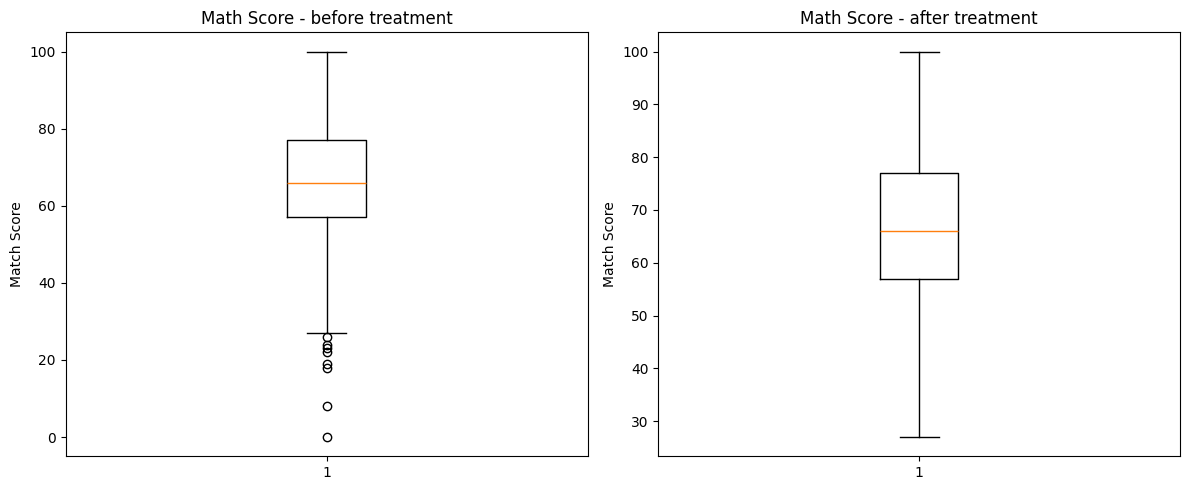

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv(r"C:\Users\Yadu krishna.M\Downloads\archive (2)\StudentsPerformance.csv")

print("first 5 rows:")
print(df.head())
print("All info:")
print(df.describe())
print(df.info())
print("shape of the dataset:")
print(df.shape)

data=df["math score"].dropna()
print("number of math score values:",len(data))

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3-Q1

lower_limit = Q1 - 1.5*IQR
upper_limit = Q3 + 1.5*IQR

print("IQR methods")
print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("lower limit",lower_limit)
print("upper limit",upper_limit)

#find IQR outliers
iqr_outliers = df[
    (df["math score"] < lower_limit) |
    (df["math score"] > upper_limit)
    ]

print("Number of IQR outliers:",len(iqr_outliers))

mean = data.mean()
std = data.std()

#calculate the z score
df["Z_score"] = (df["math score"] - mean) / std

#identify the values witht the absolute z score greater than 3
z_outliers = df[abs(df["Z_score"]) > 3]

print("\nZ-score method")
print("Mean:",mean)
print("Standard deviation:", std)
print("Number of z score outliers", len(z_outliers))

#display the outliers
print("\nIQR outliers")
if len(iqr_outliers)>0:
    print(iqr_outliers[["math score"]])
else:
    print("No IQR outliers found")

print("Z-Score outliers")
if len(z_outliers) > 0:
    print(z_outliers[["math score", "Z_score"]])
else:
    print("No Z-score outliers found")


df["math_score_treated"]= df["math score"].clip(
    lower=lower_limit,
    upper=upper_limit
    )

print("Treatment method: Cappimg using IQR limits")


print("before treatment")
print(df["math score"].describe())
print("after treatment")
print(df["math_score_treated"].describe())

comparision = df[
    ["math score", "math_score_treated"]
    ]
print(comparision.head(20))

plt.figure(figsize=(12,5))
#before treatment
plt.subplot(1,2,1)
plt.boxplot(df["math score"].dropna())
plt.title("Math Score - before treatment")
plt.ylabel("Match Score")

#after treatment
plt.subplot(1,2,2)
plt.boxplot(df["math_score_treated"].dropna())
plt.title("Math Score - after treatment")
plt.ylabel("Match Score")

#adjust spacing
plt.tight_layout()

plt.show()